# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [15]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [16]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [17]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# 1.1 Wczytanie danych
df = pd.read_csv("szkolnictwo_wysze.csv", sep=";")
print("Pierwsze wiersze:\n", df.head())
print("Wymiary:", df.shape)
print("Typy kolumn:\n", df.dtypes)

Pierwsze wiersze:
                  name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie
Wymiary: (65, 4)
Typy kolumn:
 name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separator to średnikk. Kolumna wartość wczytuje się jako typ liczbowy całkowity (int64), a nazwy kolumn z polskimi znakami wczytują się poprawnie (dzięki kodowaniu UTF-8, które jesst domyślne).

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [19]:
print("Zmienne i liczba wierszy:\n", df['zmienna'].value_counts())
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")


Zmienne i liczba wierszy:
 zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [20]:
roznica = (szeroka['kobiety'] + szeroka['mężczyźni']) - szeroka['ogółem']
print("Różnica (kobiety + mężczyźni) - ogółem:\n", roznica)

Różnica (kobiety + mężczyźni) - ogółem:
 rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [21]:
print("Statystyki opisowe:\n", szeroka.describe())
zmiana_proc = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
print("Zmiana procentowa 2012->2024:\n", zmiana_proc)

szeroka['udzial_kobiet'] = szeroka['kobiety'] / szeroka['ogółem']
szeroka['studenci_na_uczelnie'] = szeroka['ogółem'] / szeroka['uczelnie']

Statystyki opisowe:
 zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00
Zmiana procentowa 2012->2024:
 zmienna
absolwenci ogółem   -41.29
kobiety             -30.22
mężczyźni           -29.14
ogółem              -29.79
uczelnie            -31.82
dtype: float64


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

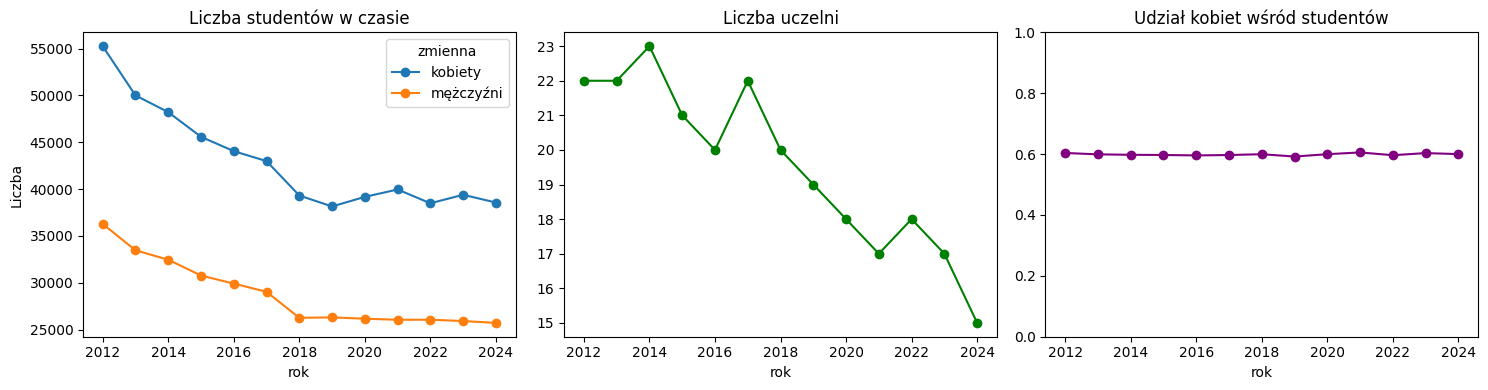

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

szeroka[['kobiety', 'mężczyźni']].plot(ax=axes[0], marker='o')
axes[0].set_title('Liczba studentów w czasie')
axes[0].set_ylabel('Liczba')

szeroka['uczelnie'].plot(ax=axes[1], marker='o', color='green')
axes[1].set_title('Liczba uczelni')

szeroka['udzial_kobiet'].plot(ax=axes[2], marker='o', color='purple')
axes[2].set_title('Udział kobiet wśród studentów')
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Liczba studentów (zarówno kobiet, jak i mężczyzn) konsekwentnie malała z każdym rokiem. Liczba uczdelni wahała się, ale ostatecznie spadła z 22 do 15. Udział kobiet wśród studentów pozostawał na stabilnym poziomie około 60% przez cały badany okres.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** zabytki · **link:** https://otwarte.miasto.lodz.pl/zabytki/ · **data pobrania:** 22.10.2026

Braki danych:
 Lp                          0
Ulica/ Aleja/ Plac          0
Numer porządkowy           13
Nazwa obiektu               0
Nr Rejestru\nZabytków    2240
dtype: int64


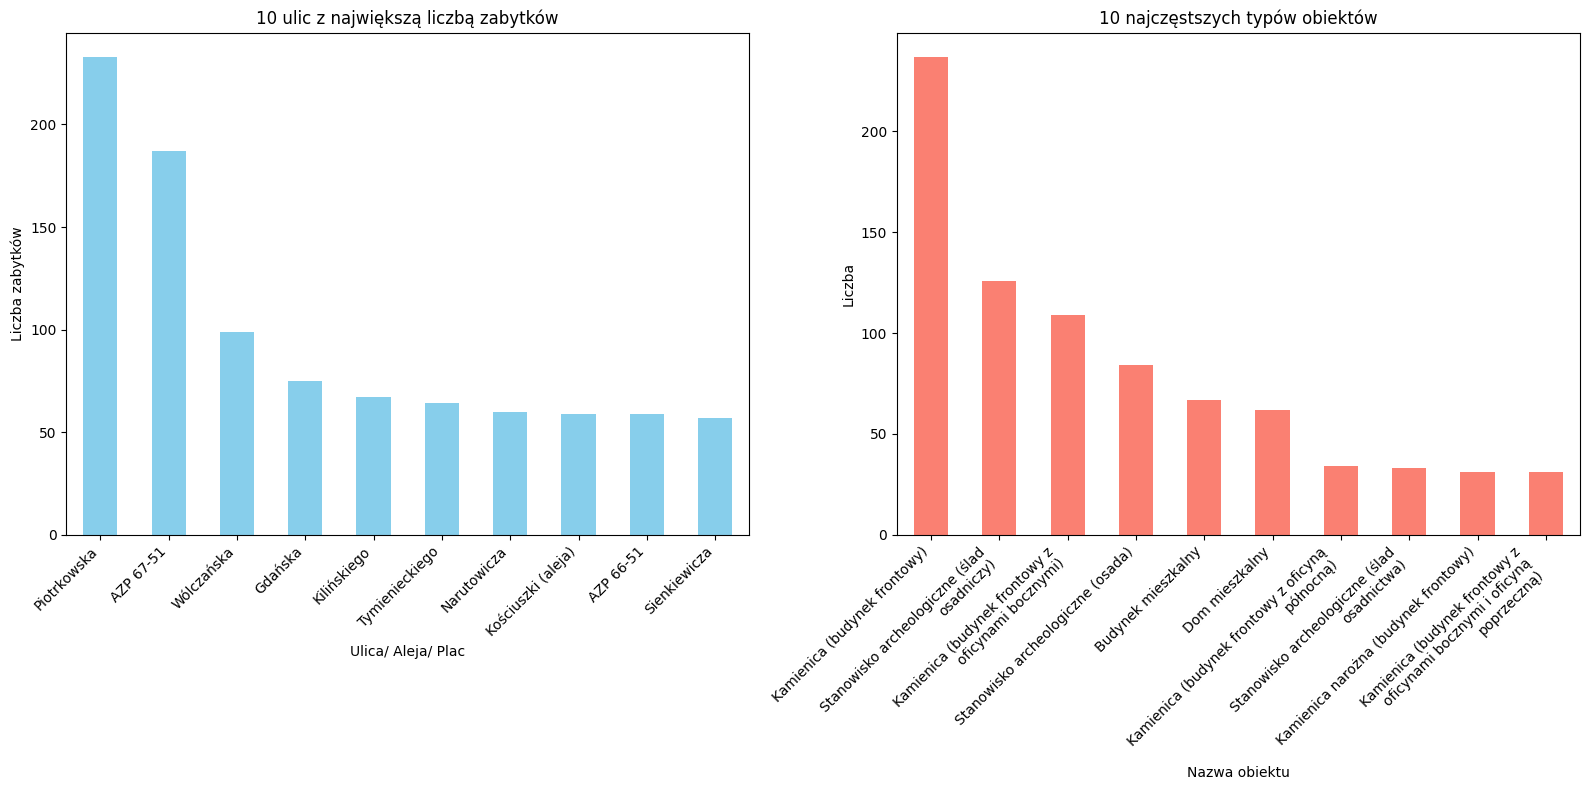

In [23]:

df_zabytki = pd.read_csv("rejestr-zabytkow.csv", sep=";")

print("Braki danych:\n", df_zabytki.isna().sum())

top_ulice = df_zabytki['Ulica/ Aleja/ Plac'].value_counts().head(10)
top_obiekty = df_zabytki['Nazwa obiektu'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

top_ulice.plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_title('10 ulic z największą liczbą zabytków')
axes[0].set_ylabel('Liczba zabytków')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

top_obiekty.plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title('10 najczęstszych typów obiektów')
axes[1].set_ylabel('Liczba')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Zdecydowana większość łódzkich zabytków zlokalizowana jest przy ulicy Piotrkowskiej, która stanowi historyczne i architektoniczne serce miasta. Dominującym typem obiektów podlegających ochronie są tradycyjne kamienice (budynki frontowe)

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [24]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

Statystyki opisowe:
           age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


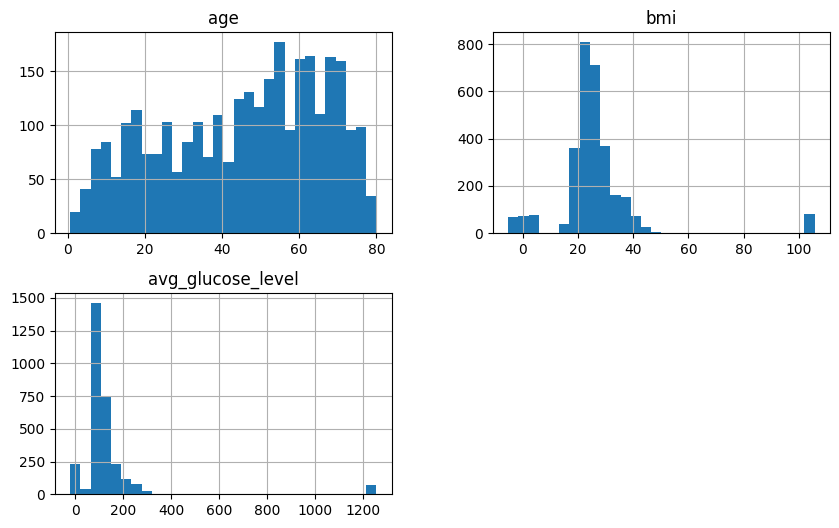

In [53]:

LICZBOWE = ["age", "bmi", "avg_glucose_level"]
URL = "https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv"
pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()

print("Statystyki opisowe:\n", pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(figsize=(10, 6), bins=30)
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

Wiek (age): Od 0 do około 120 lat.

BMI: Od około 10  do 100-150 w rzadkich przypadkach ekstremalnej otyłości (wartości ujemne, jak widoczne w statystykach -5,2, są fizycznie niemożliwe).

Średni poziom glukozy (avg_glucose_level): Od około 20 mg/dl do około 1000-1500 mg/dl (stężenie we krwi nie może być ujemne, co całkowicie wyklucza obecną w danych wartość -21,40).

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [58]:

zle_bmi = ~pacjenci['bmi'].between(10, 60)
zla_glukoza = ~pacjenci['avg_glucose_level'].between(20, 800)
zly_wiek = ~pacjenci['age'].between(0, 120)


print(f"Złe BMI: {zle_bmi.sum()}, Zła glukoza: {zla_glukoza.sum()}, Zły wiek: {zly_wiek.sum()}")


zle_razem = (zle_bmi | zla_glukoza | zly_wiek).sum()
print(f"Liczba pacjentów z co najmniej jedną niemożliwą wartością: {zle_razem}")


pacjenci.loc[zle_bmi, 'bmi'] = np.nan
pacjenci.loc[zla_glukoza, 'avg_glucose_level'] = np.nan
pacjenci.loc[zly_wiek, 'age'] = np.nan

Złe BMI: 300, Zła glukoza: 300, Zły wiek: 0
Liczba pacjentów z co najmniej jedną niemożliwą wartością: 560


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

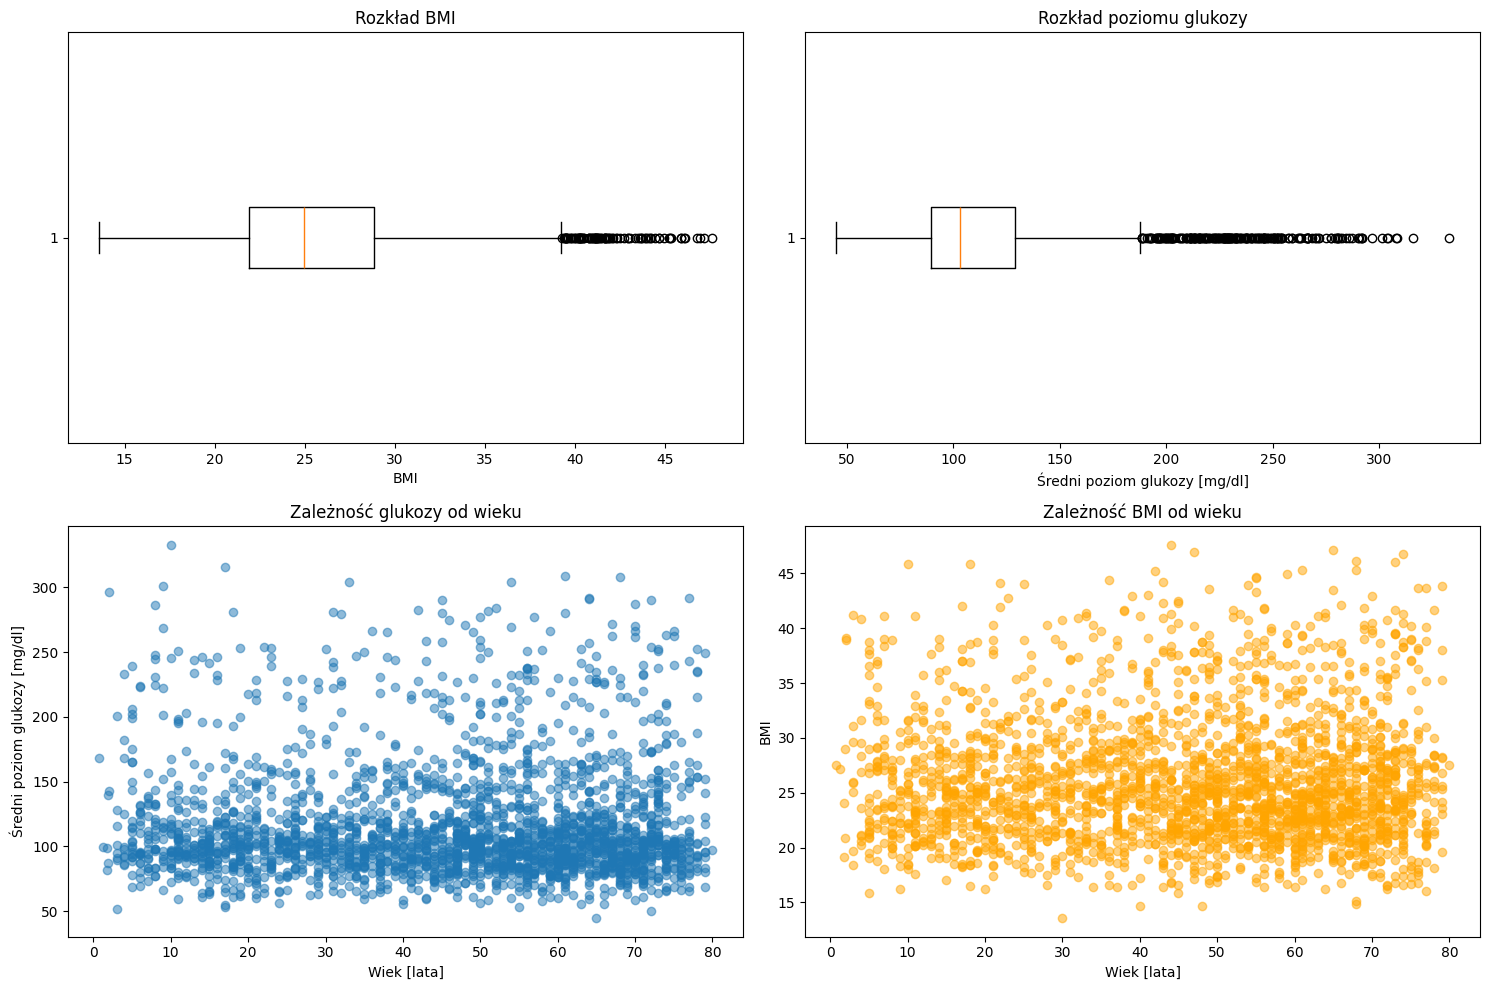

In [59]:
import matplotlib.pyplot as plt

df_clean = pacjenci.dropna(subset=['age', 'bmi', 'avg_glucose_level'])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].boxplot(df_clean['bmi'], vert=False)
axes[0, 0].set_title('Rozkład BMI')
axes[0, 0].set_xlabel('BMI')

axes[0, 1].boxplot(df_clean['avg_glucose_level'], vert=False)
axes[0, 1].set_title('Rozkład poziomu glukozy')
axes[0, 1].set_xlabel('Średni poziom glukozy [mg/dl]')


axes[1, 0].scatter(df_clean['age'], df_clean['avg_glucose_level'], alpha=0.5)
axes[1, 0].set_title('Zależność glukozy od wieku')
axes[1, 0].set_xlabel('Wiek [lata]')
axes[1, 0].set_ylabel('Średni poziom glukozy [mg/dl]')

axes[1, 1].scatter(df_clean['age'], df_clean['bmi'], alpha=0.5, color='orange')
axes[1, 1].set_title('Zależność BMI od wieku')
axes[1, 1].set_xlabel('Wiek [lata]')
axes[1, 1].set_ylabel('BMI')

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* 1. Znacznie więcej punktów poza wąsami występuje dla zmiennej opisującej średni poziom glukozy (avg_glucose_level). Ze względu na silnie prawoskośnyr rozkład tej cechy, wartości odstające leżą wyłącznie po jednej stronie pudełka.powyżej górnego wąsa (stanowiąc prawy ogon rozkładu).

2. Wykres punktowy pokazuje jednoznacznie, że wysokie poziomy glukozy występują u pacjentów w każdym wieku, a nie tylko w konkretnych przedziałach. Przypadek 10-latka ze średnią glukozą przekraczającą 300 mg/dl jest fizjologicznie niezwykle rzadki i ekstremalny, jednak w kontekście tego konkretnego, celowo "zepsutego" zbioru syntetycznego, należy traktować go jako sztucznie wprowadzony błąd i anomalię.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [28]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    z_m = 0.6745 * (s - med) / mad
    return z_m.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [49]:
pporownanie = pd.DataFrame(index=LICZBOWE, columns=['IQR 1.5', 'IQR 3', 'z-score 3', 'MAD 3.5', 'skew'])
for col in LICZBOWE:
    porownanie.loc[col, 'IQR 1.5'] = maska_iqr(pacjenci[col], k=1.5).sum()
    porownanie.loc[col, 'IQR 3'] = maska_iqr(pacjenci[col], k=3.0).sum()
    porownanie.loc[col, 'z-score 3'] = maska_z(pacjenci[col], prog=3).sum()
    porownanie.loc[col, 'MAD 3.5'] = maska_mad(pacjenci[col], prog=3.5).sum()
    porownanie.loc[col, 'skew'] = pacjenci[col].skew()

print(porownanie)

odsetek_udarow_odstajace = pacjenci.loc[maska_iqr(pacjenci['avg_glucose_level']), 'stroke'].mean()
odsetek_udarow_typowe = pacjenci.loc[~maska_iqr(pacjenci['avg_glucose_level']), 'stroke'].mean()
print(f"Udary (odstająca glukoza): {odsetek_udarow_odstajace:.2%}, typowa: {odsetek_udarow_typowe:.2%}")

                  IQR 1.5 z-score 3 MAD 3.5  skew  IQR 3
age                     0         0       0 -0.33   0.00
bmi                   100        23      33  0.99   0.00
avg_glucose_level     235        62     223  1.80  81.00
Udary (odstająca glukoza): 21.70%, typowa: 21.92%


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza ma silnie asymetryczny (prawoskośny) rozkład z długim ogonem. Metody takie jak IQR czy z-score zakładają symetryczność danych, przez co błędnie klasyfikują ten naturalny ogon jako zbiór wartości odstających. Z kolei rozkład wieku jest niemal symetryczny i pozbawiony skrajnych wartości, dlatego te same metody nie wykrywają w nim żadnych anomalii

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

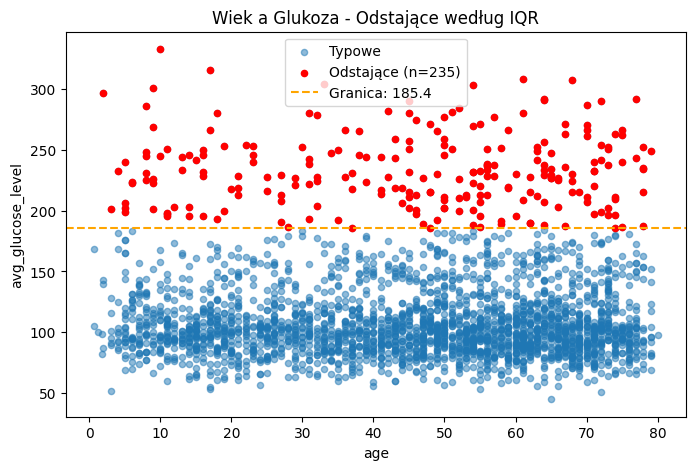

In [30]:

fig, ax = plt.subplots(figsize=(8, 5))
odstajaca_glukoza = maska_iqr(pacjenci["avg_glucose_level"])
q3 = pacjenci["avg_glucose_level"].quantile(0.75)
iqr = q3 - pacjenci["avg_glucose_level"].quantile(0.25)
granica = q3 + 1.5 * iqr


pacjenci.plot.scatter(x="age", y="avg_glucose_level", ax=ax, alpha=0.5, label="Typowe")
pacjenci[odstajaca_glukoza].plot.scatter(x="age", y="avg_glucose_level", ax=ax, color="red", label=f"Odstające (n={odstajaca_glukoza.sum()})")
ax.axhline(granica, color="orange", linestyle="--", label=f"Granica: {granica:.1f}")

ax.legend()
plt.title("Wiek a Glukoza - Odstające według IQR")
plt.show()

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów (glukoza odstająca): 0.2170212765957447
Odsetek udarów (glukoza typowa): 0.21916817359855334


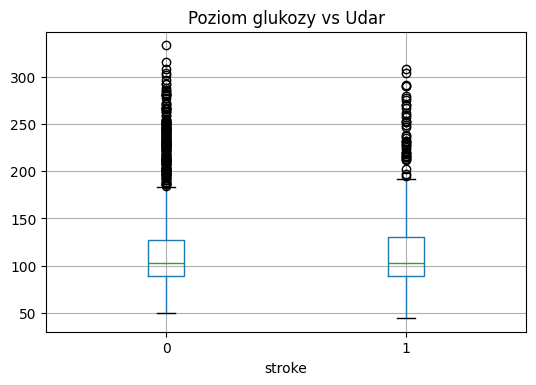

In [31]:

print("Odsetek udarów (glukoza odstająca):", pacjenci.loc[odstajaca_glukoza, 'stroke'].mean())
print("Odsetek udarów (glukoza typowa):", pacjenci.loc[~odstajaca_glukoza, 'stroke'].mean())


pacjenci.boxplot(column="avg_glucose_level", by="stroke", figsize=(6, 4))
plt.title("Poziom glukozy vs Udar")
plt.suptitle("")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie, pacjenci ci statystycznie częściej mają udary. Wartość ta (choć skrajna) niesie silną wartość informacyjną w predykcji. Zamiast usuwania powinno się pozostawić te dane i zastosować modele niewrażliwe na ekstrema.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [37]:

print("Tabela krzyżowa work_type x smoking_status:\n")
print(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))
print("-" * 50)


dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")
print(f"Dziecko pali: {dziecko_pali.sum()}, Maluch student: {maluch_student.sum()}")


print(pacjenci[dziecko_pali | maluch_student])

Tabela krzyżowa work_type x smoking_status:

smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75
--------------------------------------------------
Dziecko pali: 15, Maluch student: 1
     patient_id  gender   age  hypertension  heart_disease  ever_married  \
52      A582477  Female  1.80             0              0         False   
111     A678646  Female  9.00             0              0         False   
290     A844121    Male 13.00             0              0         False   
336     A135365  Female 12.00             0              0  

✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie, ponieważ metody te badają każdą zmienną liczbową z osobna. Wartości takie jak "dziecko" czy "pali" analizowane pojedynczo są w pełni poprawne, błędem jest dopiero ich krzyżowa kombinacja, do wykrycia której potrzebne są reguły z wiedzy dziedzinowej.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [38]:
from scipy.stats import chi2


X = pacjenci[LICZBOWE].dropna().copy()


Z = (X - X.mean()) / X.std()
d2 = (Z**2).sum(axis=1)


prog = chi2.ppf(0.99, df=3)
odstajacy_d2 = d2 > prog
print(f"Próg chi2 (0.99, df=3): {prog:.2f}")
print(f"Liczba pacjentów przekraczających próg (bez transformacji): {odstajacy_d2.sum()}")


najwiekszy_udzial = (Z.loc[odstajacy_d2]**2).idxmax(axis=1)
print("\nCecha o największym udziale w d2 wśród odstających:\n", najwiekszy_udzial.value_counts())

Próg chi2 (0.99, df=3): 11.34
Liczba pacjentów przekraczających próg (bez transformacji): 73

Cecha o największym udziale w d2 wśród odstających:
 avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Ilu przekracza próg po transformacji log: 31

Korelacje między zmiennymi:
                    age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


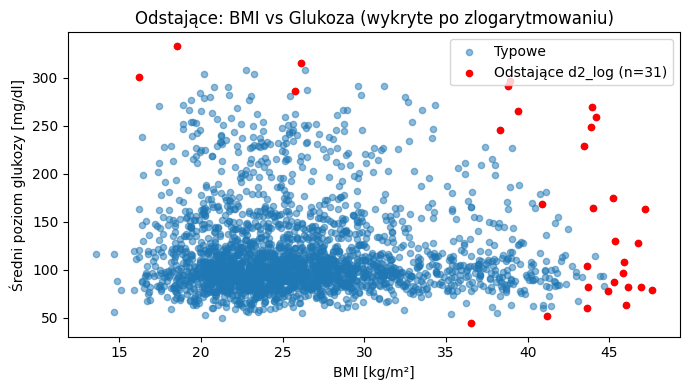

In [40]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log**2).sum(axis=1)
odstajacy_log = d2_log > prog

print(f"Ilu przekracza próg po transformacji log: {odstajacy_log.sum()}")
print("\nKorelacje między zmiennymi:\n", X.corr())

fig, ax = plt.subplots(figsize=(7, 4))
X.plot.scatter(x="bmi", y="avg_glucose_level", ax=ax, alpha=0.5, label="Typowe")
X.loc[odstajacy_log].plot.scatter(
    x="bmi", y="avg_glucose_level", ax=ax, color="red",
    label=f"Odstające d2_log (n={odstajacy_log.sum()})"
)
ax.set_xlabel("BMI [kg/m²]")
ax.set_ylabel("Średni poziom glukozy [mg/dl]")
ax.legend()
plt.title("Odstające: BMI vs Glukoza (wykryte po zlogarytmowaniu)")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

Nie, w przypadku braku korelacji między zmiennymi odległość Mahalanobisa nie da niczego więcej. W takiej sytuacji redukuje się ona matematycznie do odległości euklidesowej obliczonej ze wskaźników z-score, dając dokładnie te same wyniki.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
from sklearn.ensemble import IsolationForest


iso = IsolationForest(contamination=0.01, random_state=0)

X_log_outliers = iso.fit_predict(X_log) == -1

wspolni = (odstajacy_log & X_log_outliers).sum()

print(f"Odstający d2_log: {odstajacy_log.sum()}")
print(f"Odstający Isolation Forest: {X_log_outliers.sum()}")
print(f"Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość d2_log: {wspolni}")

## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [43]:
flagi = pd.DataFrame(index=oryginal.index)
flagi['niemozliwa_wartosc'] = zle_bmi | zla_glukoza | zly_wiek
flagi['glukoza_iqr'] = maska_iqr(pacjenci['avg_glucose_level'])
flagi['nielogiczna_kategoria'] = dziecko_pali | maluch_student
flagi['odlegly_od_srodka'] = False
flagi.loc[X_log.index, 'odlegly_od_srodka'] = (d2_log > prog)

print("Liczba pacjentów z poszczególnymi flagami:\n", flagi.sum())
print(f"\nLiczba pacjentów z co najmniej jedną flagą: {flagi.any(axis=1).sum()}")

Liczba pacjentów z poszczególnymi flagami:
 niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64

Liczba pacjentów z co najmniej jedną flagą: 806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe |Zamienić na NaN|Są to jednoznaczne błędy fizyczne (nie rzadkie jednostki z medycznego punktu widzenia), a zamiana ich na braki uchroni parametry modelu|
| wysoka glukoza (IQR) | Zostawić| Pomimo tego, że to dane silnie odstające statystycznie, korelują i wnoszą użyteczne informacje przy modelowaniu zjawiska udaru (predykcja)|
| nielogiczne kategorie | Usunąć wiersz (lub NaN)| Złamana spójność biznesowo/biologiczna wskazuje błędy techniczne, których nie powinniśmy analizować|
| odlegli od środka | Oznaczyć flagą| Mogą kryć bardzo rzadki i użyteczny profil (profil "innej populacji") lub wielowymiarowe błędy. Oflagowanie daje informację modelowi bez kasowania punktów wejściowych.|